# AWDP Project

Hello, my name is Krzysztof Wiosna and this is my analysis made in regard to the [California Housing Prices Dataset](https://www.kaggle.com/datasets/camnugent/california-housing-prices/data) found on Kaggle. This data comes from California census, performed in 1990. We will ask a few questions regarding the dataset, such as:
- Are coastal buildings more populated on average than inland ones?
- Do the newer houses have more rooms than the older ones?
- What is the median of the median incomes depending on the closeness of households and their inhabitants to the ocean?

In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

households = pd.read_csv('housing.csv')

households.head(5)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## Introduction to the dataset 

It consists of 10 variables, which are:

- longitude - which informs about where the household is on the east-west direction. The higher value it has, the more western placement the house has. (float)
- latitude - gives information about where the house is placed on the north-south direction. The higher value it has, the more northern placement the house has. (float)
- housing_median_age - median age of a house in a block; the lower the number, the younger the building (integer)
- total_rooms - overall room number in a block (integer)
- total_bedrooms - overall bedroom number in a block (integer)
- population - how many people live in a block (integer)
- households - number of households in a single block (integer)
- median_income - median income of all households in a block, measured in tens of thousands of USD (float)
- median_house_value - median house value of all houses in a block, measured in USD (float)
- ocean_proximity - house closeness and location relative to the ocean, having the following values: <1H OCEAN, INLAND, NEAR OCEAN, NEAR BAY, ISLAND (string)

In [70]:
households.shape

(20640, 10)

## Data wrangling

As we can see, the number of all rows is equal to 20640. Now let's check if the data is clean.

In [71]:
households.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


<Axes: >

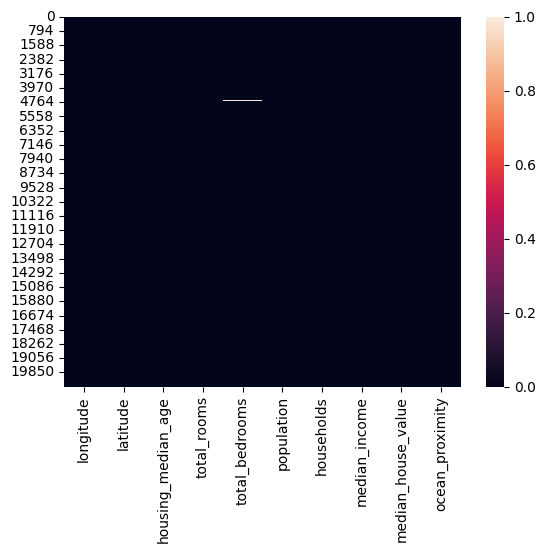

In [72]:
sns.heatmap(households.isna())

While most columns are intact, there is a lack of information about some of the bedrooms numbers in buildings. The missing data amount is actually so small that we can't really tell what is the reason for such missingness.

In [73]:
no_bedrooms = households[households['total_bedrooms'].isnull()]
no_bedrooms.head(5)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
290,-122.16,37.77,47.0,1256.0,NaN,570.0,218.0,4.3750,161900.0,NEAR BAY
341,-122.17,37.75,38.0,992.0,NaN,732.0,259.0,1.6196,85100.0,NEAR BAY
538,-122.28,37.78,29.0,5154.0,NaN,3741.0,1273.0,2.5762,173400.0,NEAR BAY
563,-122.24,37.75,45.0,891.0,NaN,384.0,146.0,4.9489,247100.0,NEAR BAY
696,-122.10,37.69,41.0,746.0,NaN,387.0,161.0,3.9063,178400.0,NEAR BAY


<Axes: xlabel='total_bedrooms', ylabel='Count'>

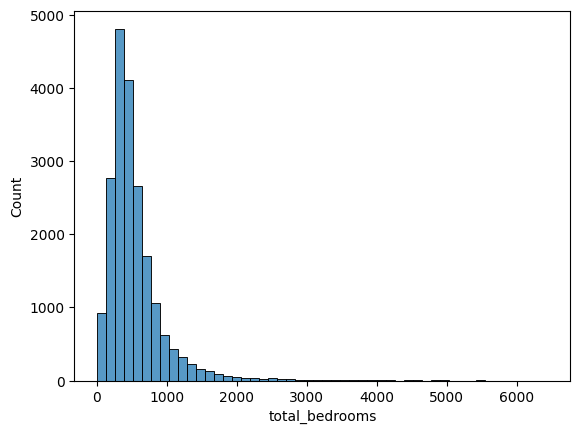

In [74]:
sns.histplot(data = households, x = 'total_bedrooms', bins = 50)

After checking this problem, we can clearly see that there are actual lacks in data. However, it's highly unlikely that in such buildings with so many rooms there aren't any bedrooms. Rows with loopholes are only about 1% of the data, so I think that we could omit them completely - they may be still valuable for the analysis, however such small value is so unsignificant that it won't change the final results, while trying to fill these values could not be accurate (total_bedrooms distribution, as we can see on the histogram, is not normal, so using median or mean while trying to fill the na's could be wrong).

In [76]:
households = households.dropna()
households.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20433 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20433 non-null  float64
 1   latitude            20433 non-null  float64
 2   housing_median_age  20433 non-null  float64
 3   total_rooms         20433 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20433 non-null  float64
 6   households          20433 non-null  float64
 7   median_income       20433 non-null  float64
 8   median_house_value  20433 non-null  float64
 9   ocean_proximity     20433 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.7+ MB


## Data Visualization

As we finally dealt with the missing data, we can start looking at it and prepare the analysis.

In [106]:
median_income_by_ocean = (households.groupby("ocean_proximity", as_index=False)["median_income"].median())

fig = px.bar(
    median_income_by_ocean,
    x="ocean_proximity",
    y="median_income",
    title="Median of median income by ocean proximity",
    category_orders={"ocean_proximity": ["<1H OCEAN", "NEAR BAY", "NEAR OCEAN", "INLAND", "ISLAND"]}
)
fig.show()

<Axes: xlabel='median_house_value', ylabel='median_income'>

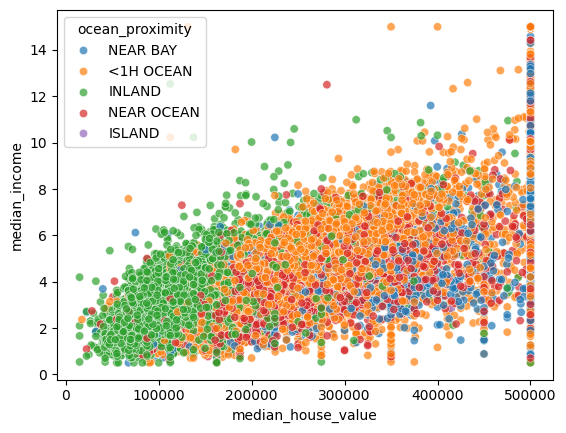

In [101]:
sns.scatterplot(data = households, x="median_house_value",
    y="median_income", hue = "ocean_proximity", alpha = .7)

As we can see on the barplot, the closer the house is to the ocean, the higher is median of median incomes in the houses in the category. The scatterplot also supports this hypothesis. However, the island households behave differently, which might be caused by the fact that their isolation from the rest of land makes them less attractive for people because of harder access to many services. Also, we know that median house value is bigger, when we get closer to the ocean, but that was rather obvious.

<Axes: xlabel='housing_median_age', ylabel='total_rooms'>

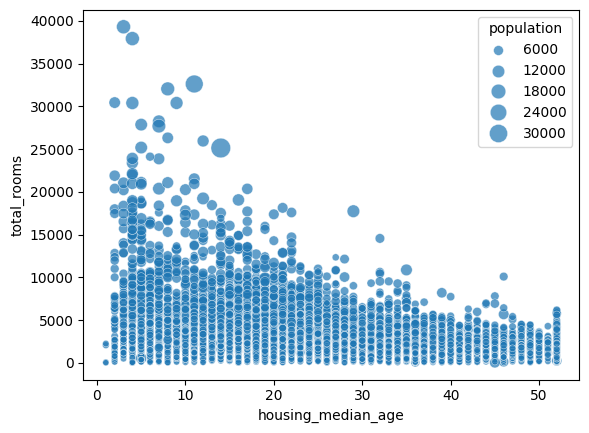

In [104]:
sns.scatterplot(data = households, x="housing_median_age",
    y="total_rooms", size = "population", sizes=(20, 200), alpha = .7)

On this scatterplot we can see another tendency. The younger the house, it usually has more rooms. However, this doesn't have to mean that there are more rooms per person in them - looking at the size of dots on the plot, we can see that buildings built more recently gathered more people inside their walls.

In [105]:
population_by_ocean = (households.groupby("ocean_proximity", as_index=False)["population"].median())

fig = px.bar(
    population_by_ocean,
    x="ocean_proximity",
    y="population",
    title="Median population by ocean proximity",
    category_orders={"ocean_proximity": ["<1H OCEAN", "NEAR BAY", "NEAR OCEAN", "INLAND", "ISLAND"]}
)
fig.show()

While we look at this barplot, we can see median population by ocean proximity. Buildings which were located less than an hour away from ocean, while island ones were much less populated. However, other buildings near ocean and inland buildings were almost samely populated.

# Conclusions from analysis

- Houses closer to the ocean's are inhabited by richer people and values of these buildings are usually bigger.
- Younger buildings usually have more rooms, however it doesn't mean more rooms per person, because these newer buildings usually have bigger population.
- Buildings located closer to the ocean have higher population on average.

### Thank you for viewing my analysis of this dataset. I hope you found it useful and acquired new, interesting information.